In [1]:
import torch
from torchvision import datasets, models, transforms

torch.manual_seed(42)

transform= transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset_path= "/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/DataSet/Cars"

In [2]:
dataset= datasets.ImageFolder(root= dataset_path + '/train', transform= transform)
test_dataset= datasets.ImageFolder(root= dataset_path + '/test', transform= transform)
class_names= dataset.classes

print('Train 폴더 이미지 수:', len(dataset))
print('Test 폴더 이미지 수:', len(test_dataset))
print('전체 이미지 수:', len(dataset) + len(test_dataset))
print('클래스 수:', len(class_names))
print('클래스명:', class_names)
print()

print('=== 회사별(폴더별) 이미지 수 ===')
for i, name in enumerate(class_names):
  train_count= dataset.targets.count(i)
  test_count= test_dataset.targets.count(i)
  print(f'{name}: Train {train_count}장 / Test {test_count}장 / 합계 {train_count + test_count}장')

Train 폴더 이미지 수: 3352
Test 폴더 이미지 수: 813
전체 이미지 수: 4165
클래스 수: 7
클래스명: ['Audi', 'Hyundai Creta', 'Mahindra Scorpio', 'Rolls Royce', 'Swift', 'Tata Safari', 'Toyota Innova']

=== 회사별(폴더별) 이미지 수 ===
Audi: Train 814장 / Test 199장 / 합계 1013장
Hyundai Creta: Train 271장 / Test 67장 / 합계 338장
Mahindra Scorpio: Train 316장 / Test 75장 / 합계 391장
Rolls Royce: Train 311장 / Test 74장 / 합계 385장
Swift: Train 424장 / Test 102장 / 합계 526장
Tata Safari: Train 441장 / Test 106장 / 합계 547장
Toyota Innova: Train 775장 / Test 190장 / 합계 965장


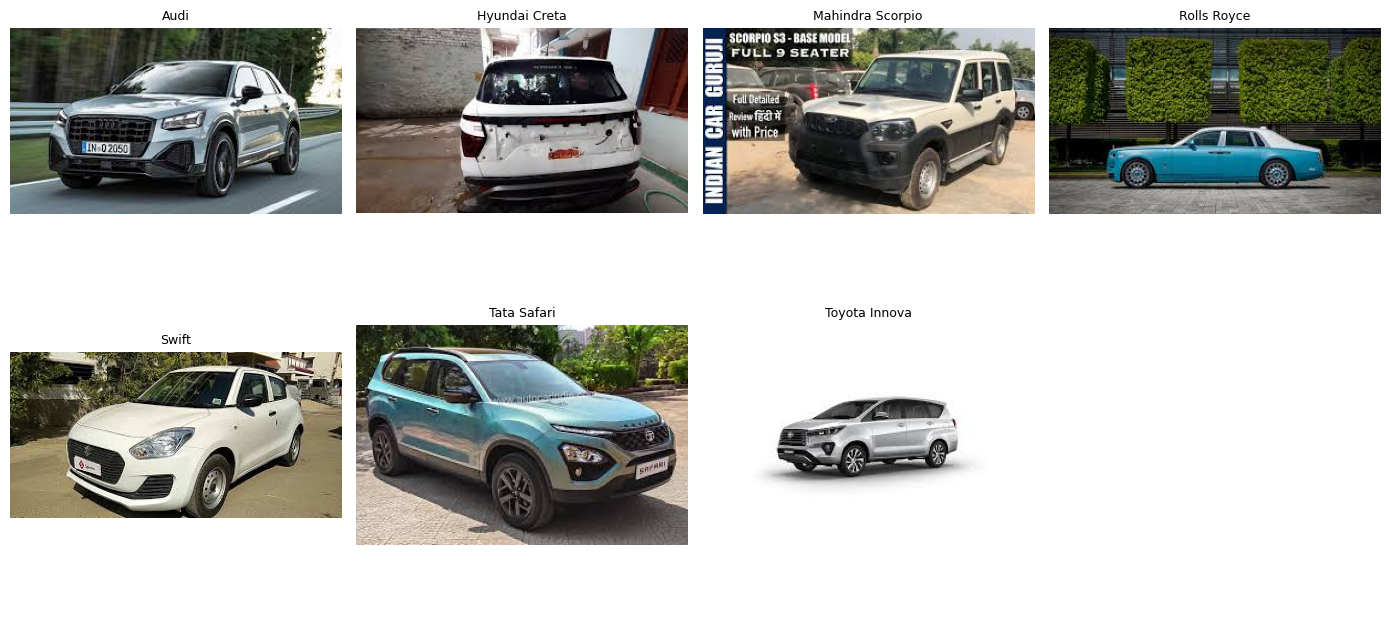

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes= plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
  if i < len(class_names):
    idx= dataset.targets.index(i)
    image_path, label= dataset.samples[idx]
    image= Image.open(image_path).convert('RGB')
    ax.imshow(image)
    ax.set_title(class_names[label], fontsize=9)
  ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
from torch.utils.data import random_split

train_dataset, val_dataset= random_split(
    dataset, [0.8, 0.2], generator= torch.Generator().manual_seed(42)
)
print('Train:', len(train_dataset))
print('Validation:', len(val_dataset))
print('Test:', len(test_dataset))

Train: 2682
Validation: 670
Test: 813


In [5]:
from torch.utils.data import DataLoader

train_loader= DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader= DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader= DataLoader(test_dataset, batch_size=16, shuffle=False)

In [6]:
device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('사용 장치:', device)

model= models.resnet50(weights='DEFAULT')
print(model.fc)

사용 장치: cpu
Linear(in_features=2048, out_features=1000, bias=True)


In [7]:
for param in model.parameters():
  param.requires_grad= False

In [8]:
import torch.nn as nn

model.fc= nn.Linear(model.fc.in_features, len(class_names))
for param in model.fc.parameters():
  param.requires_grad= True

model= model.to(device)
print(model.fc)

total_params= sum( p.numel() for p in model.parameters() if p.requires_grad )
print('학습할 파라미터 수:', total_params)

Linear(in_features=2048, out_features=7, bias=True)
학습할 파라미터 수: 14343


In [9]:
import torch.optim as optim

criterion= nn.CrossEntropyLoss()
optimizer= optim.Adam( model.fc.parameters(), lr= 0.001 )

In [10]:
epochs= 3

for epoch in range(epochs):
  model.eval()

  epoch_loss= 0
  epoch_accuracy= 0

  for images, labels in train_loader:
    images= images.to(device)
    labels= labels.to(device)

    optimizer.zero_grad()
    outputs= model(images)
    loss= criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    epoch_loss += loss.item() * images.size(0)
    predictions= outputs.argmax(dim=1)
    epoch_accuracy += (predictions == labels).sum().item()

  val_loss= 0
  val_correct= 0
  with torch.no_grad():
    for images, labels in val_loader:
      images= images.to(device)
      labels= labels.to(device)

      outputs= model(images)
      loss= criterion(outputs, labels)

      predictions= outputs.argmax(dim=1)
      val_loss += loss.item() * images.size(0)
      val_correct += (predictions == labels).sum().item()

  print(f'Epoch {epoch + 1}/{epochs} | '
          f'Train Loss: {epoch_loss / len(train_dataset):.4f} | '
          f'Train Accuracy: {100 * epoch_accuracy / len(train_dataset):.2f}% | '
          f'Val Loss: {val_loss / len(val_dataset):.4f} | '
          f'Val Accuracy: {100 * val_correct / len(val_dataset):.2f}%')

Epoch 1/3 | Train Loss: 1.2702 | Train Accuracy: 60.89% | Val Loss: 0.9394 | Val Accuracy: 71.79%
Epoch 2/3 | Train Loss: 0.7497 | Train Accuracy: 80.91% | Val Loss: 0.7044 | Val Accuracy: 81.19%
Epoch 3/3 | Train Loss: 0.5636 | Train Accuracy: 87.25% | Val Loss: 0.5984 | Val Accuracy: 84.48%


In [11]:
model.eval()
test_loss= 0
correct= 0
total= 0
y_true=[]
y_pred=[]

with torch.no_grad():
  for images, labels in test_loader:
    images= images.to(device)
    labels= labels.to(device)
    outputs= model(images)
    loss= criterion(outputs, labels)
    predictions= outputs.argmax(dim=1)

    test_loss += loss.item() * images.size(0)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    y_true.extend(labels.cpu().tolist())
    y_pred.extend(predictions.cpu().tolist())

print(f"TEST LOSS: {test_loss / total:.4f}")
print(f"TEST ACCURACY: {100 * correct / total:.2f}%")

TEST LOSS: 0.5334
TEST ACCURACY: 88.07%


                  precision    recall  f1-score   support

            Audi     0.8475    0.9497    0.8957       199
   Hyundai Creta     0.8750    0.7313    0.7967        67
Mahindra Scorpio     0.8875    0.9467    0.9161        75
     Rolls Royce     0.9286    0.7027    0.8000        74
           Swift     0.8687    0.8431    0.8557       102
     Tata Safari     0.8349    0.8585    0.8465       106
   Toyota Innova     0.9368    0.9368    0.9368       190

        accuracy                         0.8807       813
       macro avg     0.8827    0.8527    0.8640       813
    weighted avg     0.8827    0.8807    0.8789       813

[혼동행렬]
[[189   2   1   1   2   4   0]
 [  2  49   3   0   4   6   3]
 [  1   0  71   1   0   1   1]
 [ 19   0   1  52   0   2   0]
 [  8   0   1   2  86   1   4]
 [  3   3   1   0   4  91   4]
 [  1   2   2   0   3   4 178]]


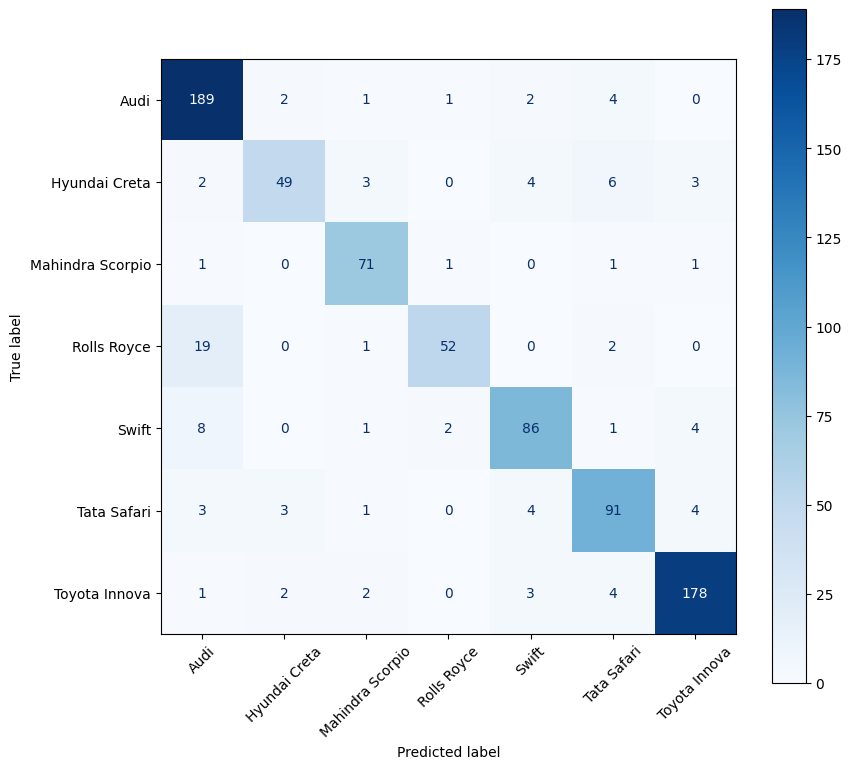

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print(classification_report(
    y_true, y_pred,
    target_names= class_names,
    labels= range(len(class_names)),
    digits=4,
    zero_division=0
))

cm= confusion_matrix(y_true, y_pred, labels= range(len(class_names)))
print('[혼동행렬]')
print(cm)

fig, ax= plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels= class_names).plot(
    ax=ax, cmap='Blues', values_format='d', xticks_rotation=45
)
plt.tight_layout()
plt.show()

In [13]:
model_path= dataset_path + '/car-resnet50-class-practice.pth'
torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': class_names
}, model_path)
print('모델 저장 완료!:', model_path)

모델 저장 완료!: /content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/DataSet/Cars/car-resnet50-class-practice.pth


In [14]:
checkpoint= torch.load(model_path, map_location= device, weights_only=True)
class_names= checkpoint['class_names']
state_dict= checkpoint['model_state_dict']

model= models.resnet50(weights=None)
model.fc= nn.Linear(model.fc.in_features, len(class_names))
model.load_state_dict(state_dict)
model= model.to(device)
model.eval()

print('모델 복원 완료! : ', class_names)

모델 복원 완료! :  ['Audi', 'Hyundai Creta', 'Mahindra Scorpio', 'Rolls Royce', 'Swift', 'Tata Safari', 'Toyota Innova']


자동차 사진 경로를 입력하세요!: /content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/Test_Images/Audi_red.png


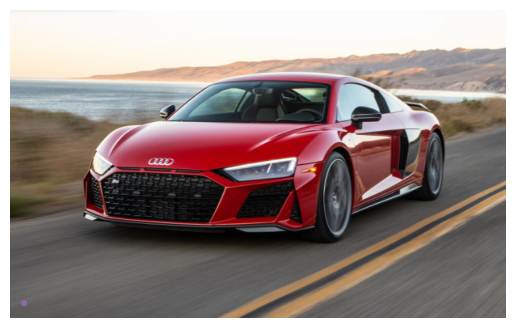

자동차 회사명 :  Audi
예측 신뢰도 : 94.87%


In [15]:
# 테스트 경로 (복사-붙여넣기 가능)
# 아  우  디 :   /content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/Test_Images/Audi_red.png
# 롤스로이스 :   /content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/Test_Images/Rolls_Royce_orange.png
#현대 크레타 :   /content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/Test_Images/Hyundai_Creta_silver.png

image_path= input('자동차 사진 경로를 입력하세요!: ').strip()
image= Image.open(image_path).convert('RGB')
plt.imshow(image)
plt.axis('off')
plt.show()

image= transform(image).unsqueeze(0).to(device)

with torch.no_grad():
  outputs= model(image)
  probabilities= torch.softmax(outputs, dim=1)
  confidence, predicted= probabilities.max(dim=1)

  print('자동차 회사명 : ', class_names[predicted.item()])
  print(f'예측 신뢰도 : {confidence.item() * 100:.2f}%')